In [48]:
# How to import the libraries
import os
import pandas as pd
import matplotlib.pyplot as plt
os.makedirs("images", exist_ok=True)
print("Pandas", pd.__version__)
print("Matplotlib:" , plt.matplotlib.__version__)
print(os.listdir("."))


Pandas 3.1.1
Matplotlib: 3.11.2
['ecommerce.ipynb', 'ecommerce_sales.csv', 'ecommerce_sales_cleaned.csv', 'images', 'insights.txt']


In [49]:
# How to load the data
df=pd.read_csv("ecommerce_sales.csv")
df.head()

,Order_ID,Order_Date,Customer_ID,Category,Product,Region,Quantity,Unit_Price,Discount,Sales,Payment_Method,Rating
0,ORD10682,2025-03-24,CUST1067,Beauty,Makeup Kit,East,1,46.85,0.00,46.85,Credit Card,4.0
1,ORD10025,2025-10-02,CUST1115,Electronics,Power Bank,West,2,24.04,0.00,48.08,Cash on Delivery,4.0
2,ORD10622,2025-07-14,CUST1386,Electronics,Wireless Earbuds,North,1,45.15,0.00,45.15,PayPal,2.0
3,ORD10100,2025-12-13,CUST1250,Electronics,Wireless Earbuds,West,1,44.37,0.05,42.15,Credit Card,5.0
4,ORD10285,2025-08-05,CUST1276,Fashion,Backpack,West,2,42.42,0.00,84.84,Debit Card,4.0


In [50]:
# How to understand the data
print("Shape:", df.shape)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate Values:\n",df.duplicated().sum())
print("\nRegions:\n",df['Region'].unique())
print("\nCategories:\n",df['Category'].unique())

Shape: (1015, 12)

Missing values:
 Order_ID           0
Order_Date         0
Customer_ID        0
Category           0
Product            0
Region             8
Quantity           0
Unit_Price         0
Discount           0
Sales              0
Payment_Method     0
Rating            13
dtype: int64

Duplicate Values:
 15

Regions:
 <StringArray>
[   'East',    'West',   'North', 'Central',   'South',    'east',    'west',
       nan,   'south',   'north', 'central']
Length: 11, dtype: str

Categories:
 <StringArray>
[        'Beauty',    'Electronics',        'Fashion', 'Home & Kitchen',
         'Sports',          'Books',         'SPORTS',    'ELECTRONICS',
        'FASHION']
Length: 9, dtype: str


In [51]:
# How to clean data
df= df.drop_duplicates()
df['Category']=df['Category'].str.strip().str.title()
df['Region']=df['Region'].str.strip().str.title()
df['Region']=df['Region'].fillna('unknown')
df['Rating']=df['Rating'].fillna(df['Rating'].median())
df['Order_Date']=pd.to_datetime(df['Order_Date'])
df['Month_Num']=df['Order_Date'].dt.month
df['Month']=df['Order_Date'].dt.strftime('%b')
print(df.shape)
print('Missing total:', df.isna().sum().sum())
print(df['Region'].unique())
print(df['Category'].unique())
df

(1000, 14)
Missing total: 0
<StringArray>
['East', 'West', 'North', 'Central', 'South', 'unknown']
Length: 6, dtype: str
<StringArray>
['Beauty', 'Electronics', 'Fashion', 'Home & Kitchen', 'Sports', 'Books']
Length: 6, dtype: str


,Order_ID,Order_Date,Customer_ID,Category,Product,Region,Quantity,Unit_Price,Discount,Sales,Payment_Method,Rating,Month_Num,Month
0,ORD10682,2025-03-24,CUST1067,Beauty,Makeup Kit,East,1,46.85,0.00,46.85,Credit Card,4.0,3,Mar
1,ORD10025,2025-10-02,CUST1115,Electronics,Power Bank,West,2,24.04,0.00,48.08,Cash on Delivery,4.0,10,Oct
2,ORD10622,2025-07-14,CUST1386,Electronics,Wireless Earbuds,North,1,45.15,0.00,45.15,PayPal,2.0,7,Jul
3,ORD10100,2025-12-13,CUST1250,Electronics,Wireless Earbuds,West,1,44.37,0.05,42.15,Credit Card,5.0,12,Dec
4,ORD10285,2025-08-05,CUST1276,Fashion,Backpack,West,2,42.42,0.00,84.84,Debit Card,4.0,8,Aug
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1010,ORD10580,2025-05-20,CUST1237,Beauty,Moisturizer,South,1,22.22,0.15,18.89,Credit Card,5.0,5,May
1011,ORD10503,2025-11-30,CUST1071,Fashion,Cotton T-Shirt,East,1,14.07,0.00,14.07,Credit Card,4.0,11,Nov
1012,ORD10538,2025-03-30,CUST1286,Fashion,Cotton T-Shirt,South,2,15.16,0.20,24.26,Debit Card,4.0,3,Mar
1013,ORD10197,2025-08-13,CUST1048,Fashion,Denim Jacket,West,1,65.01,0.05,61.76,PayPal,4.0,8,Aug


In [52]:
# How to analysis Data

# Q1: which month is best?
monthly = df.groupby(['Month_Num', 'Month'])['Sales'].sum().reset_index()
monthly = monthly.sort_values("Month_Num")
monthly

,Month_Num,Month,Sales
0,1,Jan,4736.85
1,2,Feb,4947.24
2,3,Mar,7404.95
3,4,Apr,5980.21
4,5,May,6158.55
5,6,Jun,6029.67
6,7,Jul,6823.09
7,8,Aug,7581.09
8,9,Sep,6184.83
9,10,Oct,7883.86


In [53]:
# Which category is best?
category= df.groupby('Category')['Sales'].sum().sort_values(ascending=False)
category

Category
Electronics       23335.21
Fashion           18893.10
Home & Kitchen    17213.48
Beauty             7922.89
Sports             6761.52
Books              2382.98
Name: Sales, dtype: float64

In [54]:
# Find Top products and Region
products=df.groupby('Product')['Sales'].sum().sort_values(ascending=False).head(10)
print(products)
region=df.groupby('Region')['Sales'].sum().sort_values(ascending=False).head(10)
print(region)

Product
Smartwatch           7605.11
Running Shoes        5504.88
Air Fryer            5293.54
Bluetooth Speaker    4882.11
Coffee Maker         4388.68
Wireless Earbuds     4248.63
Denim Jacket         3934.49
Laptop Stand         3197.35
Winter Coat          3132.94
Backpack             3051.03
Name: Sales, dtype: float64
Region
North      18233.04
South      16132.41
East       15861.08
West       15044.11
Central    10575.20
unknown      663.34
Name: Sales, dtype: float64


In [55]:
# How much did sales drop in winter?
winter=monthly[monthly['Month_Num'].isin([12,1,2])]['Sales'].mean()
other=monthly[~monthly['Month_Num'].isin([12,1,2])]['Sales'].mean()
drop=(1-winter/other)*100
print(f"Winter drop : {drop:.1f}%")
print("Total sales:",round(df["Sales"].sum(),2))
print("Total orders:", len(df))

Winter drop : 31.8%
Total sales: 76509.18
Total orders: 1000


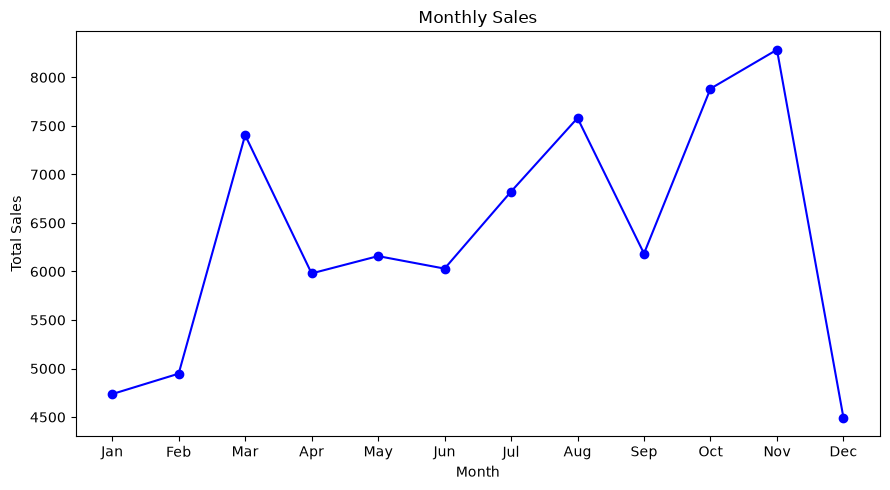

In [56]:
# Draw charts for Data visualization
plt.figure(figsize=(9,5))
plt.plot(monthly['Month'],monthly['Sales'],marker='o', color="Blue" )
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig("images/1_monthly_sales.png", dpi=150)
plt.show()

In [57]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("images", exist_ok=True)

df = pd.read_csv("ecommerce_sales.csv")
df = df.drop_duplicates()
df["Category"] = df["Category"].str.strip().str.title()
df["Region"] = df["Region"].str.strip().str.title()
df["Region"] = df["Region"].fillna("Unknown")
df["Rating"] = df["Rating"].fillna(df["Rating"].median())
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df["Month_Num"] = df["Order_Date"].dt.month
df["Month"] = df["Order_Date"].dt.strftime("%b")

print(df.shape)
df

(1000, 14)


,Order_ID,Order_Date,Customer_ID,Category,Product,Region,Quantity,Unit_Price,Discount,Sales,Payment_Method,Rating,Month_Num,Month
0,ORD10682,2025-03-24,CUST1067,Beauty,Makeup Kit,East,1,46.85,0.00,46.85,Credit Card,4.0,3,Mar
1,ORD10025,2025-10-02,CUST1115,Electronics,Power Bank,West,2,24.04,0.00,48.08,Cash on Delivery,4.0,10,Oct
2,ORD10622,2025-07-14,CUST1386,Electronics,Wireless Earbuds,North,1,45.15,0.00,45.15,PayPal,2.0,7,Jul
3,ORD10100,2025-12-13,CUST1250,Electronics,Wireless Earbuds,West,1,44.37,0.05,42.15,Credit Card,5.0,12,Dec
4,ORD10285,2025-08-05,CUST1276,Fashion,Backpack,West,2,42.42,0.00,84.84,Debit Card,4.0,8,Aug
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1010,ORD10580,2025-05-20,CUST1237,Beauty,Moisturizer,South,1,22.22,0.15,18.89,Credit Card,5.0,5,May
1011,ORD10503,2025-11-30,CUST1071,Fashion,Cotton T-Shirt,East,1,14.07,0.00,14.07,Credit Card,4.0,11,Nov
1012,ORD10538,2025-03-30,CUST1286,Fashion,Cotton T-Shirt,South,2,15.16,0.20,24.26,Debit Card,4.0,3,Mar
1013,ORD10197,2025-08-13,CUST1048,Fashion,Denim Jacket,West,1,65.01,0.05,61.76,PayPal,4.0,8,Aug


In [58]:
category = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
category

Category
Electronics       23335.21
Fashion           18893.10
Home & Kitchen    17213.48
Beauty             7922.89
Sports             6761.52
Books              2382.98
Name: Sales, dtype: float64

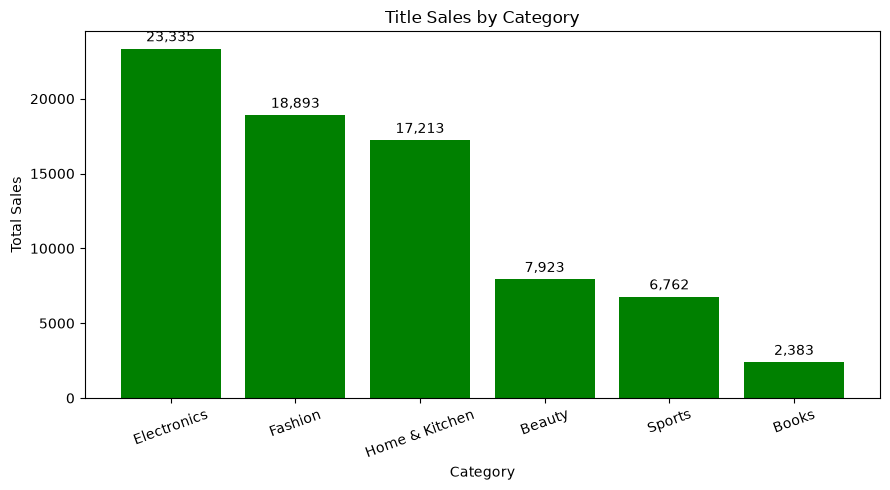

In [59]:
# sales by Category

plt.figure(figsize=(9,5))
bars=plt.bar(category.index, category.values,  color='green')
plt.bar_label(bars, labels=[f'{v:,.0f}' for v in category.values], padding=3)
plt.title('Title Sales by Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("images/2_sales_by_category.png", dpi=150)
plt.show()



Product
Smartwatch           7605.11
Running Shoes        5504.88
Air Fryer            5293.54
Bluetooth Speaker    4882.11
Coffee Maker         4388.68
Wireless Earbuds     4248.63
Denim Jacket         3934.49
Laptop Stand         3197.35
Winter Coat          3132.94
Backpack             3051.03
Name: Sales, dtype: float64


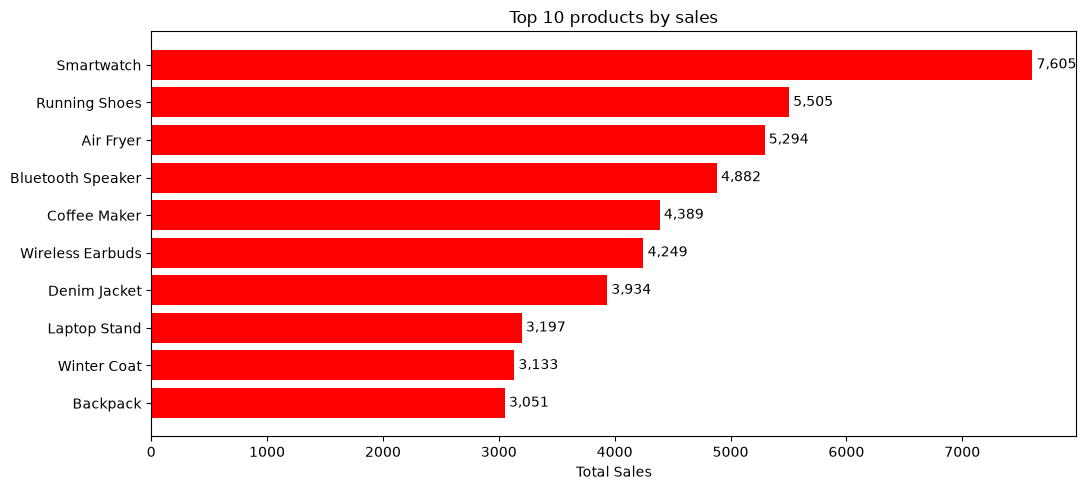

In [60]:
# Find top 10 products
products=df.groupby('Product')['Sales'].sum().sort_values(ascending=False).head(10)
print(products)

top=products.sort_values()
plt.figure(figsize=(11,5))
bars= plt.barh(top.index, top.values, color='red')
plt.bar_label(bars, labels=[f"{v:,.0f}" for v in top.values], padding=3)
plt.title("Top 10 products by sales")
plt.xlabel("Total Sales")
plt.tight_layout()
plt.savefig('images/3_top_products.png', dpi=150)
plt.show()


Region
North      18233.04
South      16132.41
East       15861.08
West       15044.11
Central    10575.20
Unknown      663.34
Name: Sales, dtype: float64


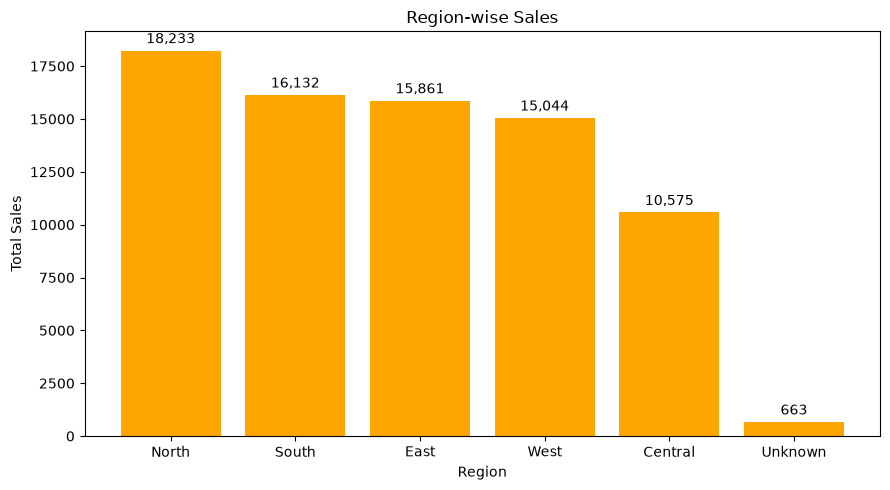

In [61]:
# Region- Wise Sales
region=df.groupby('Region')['Sales'].sum().sort_values(ascending=False).head(10)
print(region)
plt.figure(figsize=(9,5))
bars=plt.bar(region.index, region.values, color='orange')
plt.bar_label(bars, labels=[f"{v:,.0f}" for v in region.values],padding=3)
plt.title("Region-wise Sales")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig("images/4_region_sales.png",dpi=150)
plt.show()

In [62]:
monthly = df.groupby(['Month_Num', 'Month'])['Sales'].sum().reset_index()
monthly = monthly.sort_values("Month_Num")
# Other results neede for the summary
category = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
products = df.groupby("Product")["Sales"].sum().sort_values(ascending=False).head(10)
region = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

winter = monthly[monthly["Month_Num"].isin([12, 1, 2])]["Sales"].mean()
other = monthly[~monthly["Month_Num"].isin([12, 1, 2])]["Sales"].mean()
drop = (1 - winter / other) * 100
# How to save Results
df.to_csv("ecommerce_sales_cleaned.csv", index=False)
lines=[
    f"Total orders: {len(df)}",
    f"Total sales: {df['Sales'].sum():,.2f}",
    f"Best month:{monthly.loc[monthly['Sales'].idxmax(),'Month']}",
    f"Best category:{category.index[0]}",
    f"Top product:{products.index[0]}",
    f"Top region:{region.index[0]}",
    f"Winter sales drop: {drop:.1f}%",
]
with open('insights.txt','w') as f:
    f.write("\n".join(lines))
print("\n".join(lines))

Total orders: 1000
Total sales: 76,509.18
Best month:Nov
Best category:Electronics
Top product:Smartwatch
Top region:North
Winter sales drop: 31.8%
